# The `jupyter` namespace

Every cell can use a global named `jupyter`. It decides how values appear in
the notebook: as Markdown, HTML, SVG, images, charts or tables instead of
plain text. It is a port of `Deno.jupyter`, the API that Deno's built-in
kernel (`deno jupyter`) gives notebooks, so notebooks and examples written
for Deno work here, and what you learn here applies there.

This page assumes no experience with Deno. The examples were run against
the kernel on Node, Deno, Bun and workerd, and the output described is what
they produced. Differences between runtimes are noted where they exist,
and summarized at the end.


| Member | What it does |
| --- | --- |
| [`jupyter.display(value, options?)`](#showing-output-with-display) | Show a value now, in the middle of a cell, or update one shown earlier. |
| [`jupyter.md`, `jupyter.html`, `jupyter.svg`](#markdown-html-and-svg) | Tagged templates that turn a string into rendered Markdown, HTML or SVG. |
| [`jupyter.image(pathOrBytes)`](#images) | Show a PNG or JPEG from a file or from bytes. |
| [`jupyter.$display`](#custom-display-for-your-own-classes) | The symbol a class implements to choose how its instances appear. |
| [`jupyter.format(value)`](#getting-a-bundle-with-format) | Compute the output for a value without showing it. |
| [`jupyter.broadcast(type, content)`](#raw-messages-with-broadcast) | Send a raw Jupyter message, for things the helpers don't cover. |
| `jupyter.comm`, `jupyter.widget` | Comms and interactive widgets: see [Widgets and comms](https://cdp-kernel.org/docs/widgets). Not in Deno. |

`prompt()` and `confirm()` are globals rather than members, and are covered
[below](#asking-for-input-prompt-and-confirm).

## How cell output works

A cell can produce output three ways:

In [1]:
const languages = ["TypeScript", "Rust", "Go"];
console.log(`${languages.length} languages`);  // stream output (stdout)
console.error("this goes to stderr");          // stream output (stderr)
languages.map((name) => name.toUpperCase());   // the cell's result

3 languages


this goes to stderr


[ 'TYPESCRIPT', 'RUST', 'GO' ]

- `console.log` and friends print text as the cell runs.
- If the cell ends with an expression, its value is the cell's **result**,
  shown under the cell (here `[ 'TYPESCRIPT', 'RUST', 'GO' ]`). A trailing
  semicolon doesn't hide it. A cell that ends with a declaration, such as
  `const total = 42;`, has no result.
- `jupyter.display()` shows a value at any point in the cell, as many times
  as you call it.

A result or displayed value isn't just text. Jupyter output is a **MIME
bundle**: an object mapping media types to data, such as
`{ "text/plain": "34°C", "text/html": "<b>34°C</b>" }`. The frontend
(JupyterLab, VS Code, Notebook) picks the richest type it can render, and
falls back to `text/plain`. Everything on this page is a way to build
those bundles. For an ordinary value such as a number, array or plain
object, the bundle has only `text/plain`, the same text `console.log`
would print.

## Markdown, HTML and SVG

`jupyter.md`, `jupyter.html` and `jupyter.svg` are
[tagged templates](https://developer.mozilla.org/en-US/docs/Web/JavaScript/Reference/Template_literals#tagged_templates):
write them directly before a template literal, with no parentheses. The
result is an object that renders as that media type, either as the cell's
result or passed to `jupyter.display`.

### Markdown

Use Markdown for reports built from data: headings, tables, emphasis,
lists and links.

In [2]:
const scores = { Ada: 92, Grace: 88, Linus: 75 };
const rows = Object.entries(scores)
  .map(([name, score]) => `| ${name} | ${score} |`)
  .join("\n");
const average = Object.values(scores).reduce((a, b) => a + b) / 3;

jupyter.md`
## Quiz results

| Name | Score |
| ---- | ----: |
${rows}

Average: **${average.toFixed(1)}**
`;


## Quiz results

| Name | Score |
| ---- | ----: |
| Ada | 92 |
| Grace | 88 |
| Linus | 75 |

Average: **85.0**


This renders a heading, a three-row table, and the average in bold.
JupyterLab and VS Code also render LaTeX math in Markdown output, such as
`` jupyter.md`$e^{i\pi} + 1 = 0$` ``.

### HTML

HTML output can use any element and inline styles. Interpolated values
are inserted **as is, without escaping**, so text from users, files or the
network can break the markup or inject a `<script>`. Escape it yourself:

In [3]:
const comment = `<script>alert("hi")</script> & more`;
const escapeHTML = (s: string) =>
  s.replace(/[&<>"']/g, (c) => `&#${c.charCodeAt(0)};`);

jupyter.html`<p>Unsafe: ${comment}</p>
<p>Safe: ${escapeHTML(comment)}</p>`;

Unsafe: & more 
 Safe: <script>alert("hi")</script> & more

The second paragraph shows the comment as literal text. The same applies
to `jupyter.md` and `jupyter.svg`.

### SVG

SVG is useful for small charts and diagrams drawn from data, with no
library:

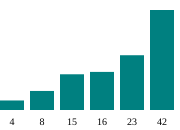

In [4]:
const data = [4, 8, 15, 16, 23, 42];
const max = Math.max(...data);
const bars = data.map((v, i) => {
  const h = (v / max) * 100;
  return `<rect x="${i * 30}" y="${110 - h}" width="24" height="${h}" fill="teal"/>
    <text x="${i * 30 + 12}" y="125" font-size="10" text-anchor="middle">${v}</text>`;
}).join("");

jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="180" height="130">${bars}</svg>`;

This draws a labeled bar chart. Include the `xmlns` attribute: some
frontends render SVG output as an image, which requires it.

## Showing output with display

`await jupyter.display(value, options?)` shows `value` immediately. Use it
to show more than one thing from a cell, or to show progress while a cell
is still running.

In [5]:
for (const step of ["fetch", "parse", "summarize"]) {
  await jupyter.display(jupyter.md`Finished **${step}**`);
}
"all done";

Finished **fetch**

Finished **parse**

Finished **summarize**

'all done'

This shows three Markdown lines, then the result `'all done'`. `value` can
be anything a cell could end with: a template from the previous section, an
image, an object with a [custom display](#custom-display-for-your-own-classes),
or a plain value, which shows as text.

`display` returns a promise. Without `await` the output still appears,
but output written later in the cell, such as a `console.log`, can appear
before it.

### Updating output in place

Give a display a `display_id`, then display again with the same id and
`update: true` to replace it instead of adding a new output. This makes
progress bars, counters and live status lines:

In [6]:
const sleep = (ms: number) => new Promise((resolve) => setTimeout(resolve, ms));
const bar = (pct: number) =>
  jupyter.html`<progress value="${pct}" max="100"></progress> ${pct}%`;

await jupyter.display(bar(0), { display_id: "download" });
for (let pct = 25; pct <= 100; pct += 25) {
  await sleep(500);
  await jupyter.display(bar(pct), { display_id: "download", update: true });
}

0%

The cell shows one progress bar that fills up. An update replaces every
output with that id, including one shown by an earlier cell, so a later
cell can change what an earlier one displayed. Pick ids that won't collide,
such as `crypto.randomUUID()`.

### Sending a MIME bundle directly

With `raw: true`, a plain object is sent as the MIME bundle itself rather
than being formatted. Use it for media types the helpers don't produce:

In [7]:
const user = { name: "Ada", roles: ["admin", "dev"], active: true };
await jupyter.display(
  {
    "application/json": user,
    "text/plain": JSON.stringify(user),
  },
  { raw: true },
);

{"name":"Ada","roles":["admin","dev"],"active":true}

JupyterLab renders `application/json` as a collapsible tree. Other useful
types are `text/latex`, `application/geo+json` (with an extension), and
`application/vnd.vegalite.v5+json`. Include `text/plain` as a fallback for
frontends that can't render the rich type.

Without `raw: true`, the same object is formatted like any other value, so
`jupyter.display({ "text/html": "<b>hi</b>" })` shows the object's text,
not bold text.

## Images

`jupyter.image` shows a PNG or JPEG. Pass a file path, relative to the
notebook's directory:

```ts
jupyter.image("./chart.png");
```

or the image's bytes as a `Uint8Array`:

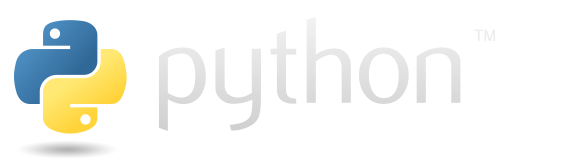

In [8]:
const response = await fetch("https://www.python.org/static/img/python-logo.png");
const logo = new Uint8Array(await response.arrayBuffer());
jupyter.image(logo);

The format is detected from the bytes, not the file name. Anything other
than PNG or JPEG throws a `TypeError`; for SVG use `jupyter.svg`. On
workerd and celld there is no file system, so pass bytes.

A `Uint8Array` holding a PNG or JPEG is shown as an image without
`jupyter.image` too (see [Values shown richly](#values-shown-richly-without-any-code)).

## Custom display for your own classes

A class can choose how its instances appear by implementing a method keyed
by the `jupyter.$display` symbol. The method returns a MIME bundle:

In [9]:
class Temperature {
  celsius: number;
  constructor(celsius: number) {
    this.celsius = celsius;
  }
  [jupyter.$display]() {
    const color = this.celsius >= 30 ? "crimson" : this.celsius <= 5 ? "steelblue" : "seagreen";
    const fahrenheit = (this.celsius * 9) / 5 + 32;
    return {
      "text/plain": `${this.celsius}°C`,
      "text/html": `<b style="color:${color}">${this.celsius}°C</b> (${fahrenheit.toFixed(1)}°F)`,
    };
  }
}

new Temperature(34);

34°C

The result is a red "34°C (93.2°F)". The method is used wherever the
object is shown: as a cell's result, through `jupyter.display`, or through
`jupyter.format`. It is not used for objects nested inside other values:
`[new Temperature(2), new Temperature(20)]` shows as plain text. Display
each one instead:

In [10]:
for (const t of [new Temperature(2), new Temperature(20)]) {
  await jupyter.display(t);
}

2°C

20°C

The method can be `async`, to fetch or compute what it shows:

In [11]:
class Weather {
  city: string;
  constructor(city: string) {
    this.city = city;
  }
  async [jupyter.$display]() {
    const forecast = await Promise.resolve("18°C, light rain"); // e.g. a fetch
    return { "text/markdown": `**${this.city}**: ${forecast}` };
  }
}

new Weather("Portland");

**Portland**: 18°C, light rain

### In a library

`jupyter.$display` is `Symbol.for("Jupyter.display")`. Code in a module,
which might also run outside a notebook, should use that form, so it
doesn't depend on the `jupyter` global:

```ts
// matrix.ts
export class Matrix {
  rows: number[][];
  constructor(rows: number[][]) {
    this.rows = rows;
  }
  [Symbol.for("Jupyter.display")]() {
    const body = this.rows.map((r) => r.join(" & ")).join(" \\\\ ");
    return { "text/latex": `$$\\begin{bmatrix} ${body} \\end{bmatrix}$$` };
  }
}
```

Outside a notebook the method is never called. A library written this way
displays the same in `deno jupyter`.

For type checking, see [Editor types](https://cdp-kernel.org/docs/editor-types): only
`jupyter.$display` carries the precise method type.

## Values shown richly without any code

A cell's result, or a value passed to `jupyter.display`, gets a rich
output when it looks like one of the objects below. The checks are by
shape (duck typing), so they work with any library that produces such
objects, without a dependency on it. They are checked in this order:

| Value | Shown as | Detected by |
| --- | --- | --- |
| Object with a `[jupyter.$display]()` method | whatever it returns | the method |
| Canvas | PNG image | a `toDataURL()` method |
| Vega or Vega-Lite chart | interactive chart | a `toSpec()` method returning a spec with `$schema` |
| DataFrame | table (HTML and `application/vnd.dataresource+json`) | `schema`, `head()` and `toRecords()` |
| `Uint8Array` of PNG or JPEG data | image | the file signature |
| SVG element | SVG | `outerHTML` starting with `<svg` |
| HTML element | HTML | an `outerHTML` string |

Anything else shows as text. Some examples with common npm packages
(see [Writing notebooks](https://cdp-kernel.org/docs/notebooks#language-and-imports) for how
`npm:` imports work):

**Charts with Vega-Lite.** [vega-lite-api](https://github.com/vega/vega-lite-api)
builds a chart in code. JupyterLab renders it as an interactive chart
with no extension.

In [12]:
import * as vl from "npm:vega-lite-api@5";

const sales = [
  { month: "Jan", sales: 28 },
  { month: "Feb", sales: 55 },
  { month: "Mar", sales: 43 },
];
vl.markBar().data(sales).encode(vl.x().fieldO("month"), vl.y().fieldQ("sales"));

A hand-written spec works too: any object whose `toSpec()` returns it.

**Tables with Polars.** A [nodejs-polars](https://pola-rs.github.io/nodejs-polars/)
DataFrame shows its first 10 rows as an HTML table (the
`dataresource` part carries 50):

In [13]:
import pl from "npm:nodejs-polars@0.18";

const df = pl.DataFrame({
  city: ["Lisbon", "Oslo", "Lima"],
  population_m: [0.55, 0.71, 10.1],
  coastal: [true, false, true],
});
df.sort("population_m", true);

city,population_m,coastal
Lima,10.1,true
Oslo,0.71,false
Lisbon,0.55,true


**Drawing with a canvas.** [@napi-rs/canvas](https://github.com/Brooooooklyn/canvas)
implements the browser's Canvas 2D API:

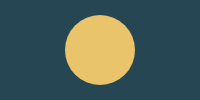

In [14]:
import { createCanvas } from "npm:@napi-rs/canvas@0.1";

const canvas = createCanvas(200, 100);
const ctx = canvas.getContext("2d");
ctx.fillStyle = "#264653";
ctx.fillRect(0, 0, 200, 100);
ctx.fillStyle = "#e9c46a";
ctx.beginPath();
ctx.arc(100, 50, 35, 0, Math.PI * 2);
ctx.fill();
canvas;

**DOM elements.** A server-side DOM such as [linkedom](https://github.com/WebReflection/linkedom)
lets you build HTML with the DOM API and show the element:

In [15]:
import { parseHTML } from "npm:linkedom@0.18";

const { document } = parseHTML("<!doctype html><html><body></body></html>");
const list = document.createElement("ul");
for (const item of ["eggs", "flour", "milk"]) {
  const li = document.createElement("li");
  li.textContent = item;
  list.append(li);
}
list;

eggs flour milk

These four examples run on Node, Deno and Bun. On workerd and celld only
vega-lite-api works: packages with native add-ons (Polars, @napi-rs/canvas)
can't be bundled for workerd, and linkedom fails on an optional import of
`canvas`. Deno's `deno jupyter` can also display WebGPU textures and
buffers; that is not supported here.

## Getting a bundle with format

`await jupyter.format(value)` returns the MIME bundle that displaying
`value` would send, without showing anything. Use it to check a custom
display, or to reuse the rendered output elsewhere:

In [16]:
const bundle = await jupyter.format(new Temperature(12));
Object.keys(bundle);  // [ 'text/plain', 'text/html' ]

[ 'text/plain', 'text/html' ]

```ts
import { writeFileSync } from "node:fs";

const report = await jupyter.format(jupyter.md`# Weekly report`);
writeFileSync("report.md", report["text/markdown"] as string);
```

For plain values the `text/plain` entry contains terminal color codes,
as the notebook shows them: `await jupyter.format(42)` returns
`{ "text/plain": "\x1b[33m42\x1b[39m" }`.

## Raw messages with broadcast

`jupyter.broadcast(msgType, content, { metadata?, buffers? })` sends a
message of any type on the kernel's output channel (IOPub), as a reply to
the running cell. The helpers above are built on it. Use it for message
types they don't cover; the [Jupyter messaging spec](https://jupyter-client.readthedocs.io/en/stable/messaging.html#messages-on-the-iopub-pub-sub-channel)
lists them.

The most useful is `clear_output`, which clears the cell's output. With
`wait: true` the old output stays until new output arrives, so it doesn't
flicker:

In [17]:
const sleep = (ms: number) => new Promise((resolve) => setTimeout(resolve, ms));

for (const n of [3, 2, 1]) {
  jupyter.broadcast("clear_output", { wait: true });
  await jupyter.display(jupyter.md`Launching in **${n}**…`);
  await sleep(1000);
}
jupyter.broadcast("clear_output", { wait: true });
"🚀";

'🚀'

The cell counts down in place and ends showing only the result. Unlike a
`display_id` update, this clears everything the cell has printed so far,
including `console.log` output.

`broadcast` sends what you give it without checking it, so a message
with the wrong fields is silently ignored or mishandled by the frontend.
Prefer the helpers when one fits.

## Asking for input: `prompt` and `confirm`

`prompt()` and `confirm()` work as in a browser, but ask in the notebook:
the frontend shows an input box under the cell, and the cell waits for
the answer.

```ts
const name = prompt("What's your name?", "world");
const shout = confirm("Shout the greeting?");
const greeting = `Hello, ${name}!`;
shout ? greeting.toUpperCase() : greeting;
```

- `prompt(message, defaultValue)` returns the typed text, or
  `defaultValue` when the answer is empty. The default is shown in the
  question as `What's your name? [world]`.
- `confirm(message)` adds `[y/N]` and returns `true` only for `y` or `Y`.
- `prompt(message, "", { password: true })` hides what is typed, for
  secrets you don't want saved in the notebook:

  ```ts
  const apiKey = prompt("API key", "", { password: true });
  ```

When nothing can answer, `prompt` returns `null` and `confirm` returns
`false`. That happens when the frontend has no input channel (some
headless runners, such as `nbconvert --execute`), and always on workerd and
celld. Code meant to run unattended should handle `null`.

## Notebooks written for Deno

Notebooks written for `deno jupyter` use `Deno.jupyter` rather than
`jupyter`. Both names refer to the same object where `Deno` exists:

| Kernel | `jupyter` | `Deno.jupyter` |
| --- | --- | --- |
| `cdp-deno` | yes | yes |
| `cdp-node-deno` | yes | yes, through the Deno compatibility shim |
| `cdp-node` | yes | no (`Deno` is undefined) |
| `cdp-bun`, `cdp-workerd`, `cdp-celld` | yes | no |

On a Deno target, Deno's own `Deno.jupyter` throws outside `deno jupyter`,
so the kernel wraps the `Deno` namespace: `Deno.jupyter` returns `jupyter`,
and everything else is Deno's.

To run an existing Deno notebook on Node, install the `cdp-node-deno`
kernel (`cdp-kernel install --runtime node --deno-compat`). It adds a
`Deno` namespace covering `Deno.jupyter` and Deno's file, environment and
process APIs (`runtime/deno-compat.mjs`). It's a separate kernel rather
than the default because libraries detect Deno with `typeof Deno`, and
would take Deno code paths that call APIs the shim doesn't cover.

New notebooks should use `jupyter`, which works on every kernel.

## Differences by runtime

Everything on this page works on every runtime, except:

| | Node, Deno | Bun | workerd, celld |
| --- | --- | --- | --- |
| `jupyter.image(path)` | yes | yes | no file system: pass bytes |
| `prompt`, `confirm` | yes | yes | return `null` / `false` |
| `Deno.jupyter` | Deno, or Node with `--deno-compat` | no | no |
| Native-add-on packages (Polars, canvas) | yes | yes | no |

What counts as a cell's result also differs slightly on Bun, workerd and
celld: only an expression statement at the very end of the cell is a
result. [Choosing a runtime](https://cdp-kernel.org/docs/runtimes) compares the runtimes, and
[Known gaps](https://cdp-kernel.org/docs/known-gaps) has the full list of differences.